<a href="https://colab.research.google.com/github/ezgitemur/GROUP18_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Exploratory Data Analysis and Baseline Models

## Introduction

This notebook is the first part of our CENG313 project, based on the Kaggle competition **CMI – Detect Behavior with Sensor Data**. The goal is to detect body-focused repetitive behaviors (BFRBs), such as hair pulling and skin picking, from data recorded by a wrist-worn device (Helios). Because BFRB-like movements can closely resemble ordinary gestures (for example, scratching the neck versus scratching the knee), a good model must recognize not only the motion but also where on the body it happens.

### Task

Each `sequence_id` is one recording of a participant performing one gesture, stored as a multivariate time series with one row per time step. The task is **sequence-level classification**: given a whole sequence, predict its gesture. The training data contains 574,945 rows in 8,151 sequences from 81 participants. Sequences are short and vary in length (29 to 700 time steps, median 59).

The device provides three kinds of sensors:

| Sensor | Columns | Description |
|---|---|---|
| IMU (7) | `acc_x/y/z`, `rot_w/x/y/z` | Acceleration and orientation quaternion |
| Thermopile (5) | `thm_1` – `thm_5` | Temperature readings |
| Time-of-Flight (320) | `tof_1_v0` – `tof_5_v63` | Proximity readings from 5 sensors, each an 8×8 pixel grid; -1 means no object detected |

About half of the hidden test set contains only IMU data, so a useful model must also work without the thermopile and ToF sensors. For this reason, our baselines are evaluated both with IMU features only and with all sensors.

### Target Variable

The target is `gesture`, with **18 classes**, constant within a sequence. Eight classes are BFRB gestures (target) and ten are non-BFRB gestures (non-target). The column `sequence_type` marks which group a sequence belongs to: 5,113 sequences (63%) are Target and 3,038 (37%) are Non-Target.

### Evaluation Metric

Submissions are scored with the average of two components:

1. **Binary F1:** whether the gesture is a BFRB or a non-BFRB gesture.
2. **Macro F1:** F1 averaged over 9 classes, namely the 8 BFRB gestures plus a single merged `non_target` class.

$$\text{Score} = \frac{\text{F1}_{\text{binary}} + \text{F1}_{\text{macro}}}{2}$$

The metric therefore rewards both detecting BFRB behavior and identifying its exact type. Confusing two non-BFRB gestures costs nothing, while confusing two BFRB gestures does. Our implementation is `competition_score` in `src/utils.py`; as a sanity check, a perfect prediction scores 1.0.

### Validation Strategy

Each participant contributes about 100 sequences. If the same person appeared in both training and validation data, scores would be inflated. We therefore use 5-fold **`GroupKFold` with participants as groups**, so every validation fold contains only unseen subjects. All models use the same folds and the same metric, which makes their scores directly comparable.

### Contents of This Notebook

1. **Exploratory data analysis:** dataset structure, gesture and sequence-length distributions, missing values, ToF "no detection" values, example signals, and participant demographics.
2. **Baseline models:** a majority-class baseline, a random forest on IMU features only, and a random forest on all sensors. Their scores form the reference point for the proposed solution in Assignment 2.

In [3]:
import os
from google.colab import userdata

# Read keys from Secrets
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Download data and extract from zip
!kaggle competitions download -c cmi-detect-behavior-with-sensor-data -p data
!unzip -q data/cmi-detect-behavior-with-sensor-data.zip -d data
!ls -lh data

cmi-detect-behavior-with-sensor-data.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/kaggle_evaluation/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/cmi_gateway.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/cmi_inference_server.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/base_gateway.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/generated/__init__.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/generated/kaggle_evaluation_pb2.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/generated/kaggle_evaluation_pb2_grpc.py? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace data/kaggle_evaluation/core/kaggle_evaluation.proto? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [4]:
 import sys

REPO_URL = "https://github.com/ezgitemur/GROUP18_CENG313.git"
REPO_DIR = "GROUP18_CENG313"

if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull
else:
    !git clone {REPO_URL}

sys.path.append(REPO_DIR)

import importlib
import src.data
importlib.reload(src.data)
from src.data import load_train, get_sensor_groups, get_sequence_labels, extract_features, summarize_tof

import src.utils
importlib.reload(src.utils)
from src.utils import competition_score

import src.models
importlib.reload(src.models)
from src.models import make_random_forest, cross_validate


remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 3.51 KiB | 128.00 KiB/s, done.
From https://github.com/ezgitemur/GROUP18_CENG313
   7d9042e..93928cf  main       -> origin/main
Updating 7d9042e..93928cf
Fast-forward
 assignment1_eda_baseline.ipynb | 225 +++++++++++++++++++++++------------------
 1 file changed, 126 insertions(+), 99 deletions(-)


**Purpose:** Download the competition data using the Kaggle API and clone the project repository to import reusable code from `src/`. Kaggle credentials are stored in Colab Secrets and are not included in this notebook.

## 2. Loading the Data
**Purpose:** Load the training data and inspect its size and first rows.

In [5]:
import pandas as pd

train = pd.read_csv("data/train.csv")
print(train.shape)
train.head()

(574945, 341)


,row_id,sequence_type,sequence_id,sequence_counter,subject,orientation,behavior,phase,gesture,acc_x,...,tof_5_v54,tof_5_v55,tof_5_v56,tof_5_v57,tof_5_v58,tof_5_v59,tof_5_v60,tof_5_v61,tof_5_v62,tof_5_v63
0,SEQ_000007_000000,Target,SEQ_000007,0,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.683594,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
1,SEQ_000007_000001,Target,SEQ_000007,1,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.949219,...,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
2,SEQ_000007_000002,Target,SEQ_000007,2,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.722656,...,-1.0,-1.0,112.0,119.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
3,SEQ_000007_000003,Target,SEQ_000007,3,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,6.601562,...,-1.0,-1.0,101.0,111.0,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
4,SEQ_000007_000004,Target,SEQ_000007,4,SUBJ_059520,Seated Lean Non Dom - FACE DOWN,Relaxes and moves hand to target location,Transition,Cheek - pinch skin,5.566406,...,-1.0,-1.0,101.0,109.0,125.0,-1.0,-1.0,-1.0,-1.0,-1.0


**Findings:** The training set has 574,945 rows and 341 columns. Each row is one time step, and rows are grouped into recordings by `sequence_id`. The target label is `gesture`.

## 3. Column Overview
**Purpose:** List the columns and group them by type.

In [6]:
print(train.columns[:20].tolist())
print("...")
print(train.columns[-5:].tolist())

['row_id', 'sequence_type', 'sequence_id', 'sequence_counter', 'subject', 'orientation', 'behavior', 'phase', 'gesture', 'acc_x', 'acc_y', 'acc_z', 'rot_w', 'rot_x', 'rot_y', 'rot_z', 'thm_1', 'thm_2', 'thm_3', 'thm_4']
...
['tof_5_v59', 'tof_5_v60', 'tof_5_v61', 'tof_5_v62', 'tof_5_v63']


**Findings:** 9 metadata columns, 7 IMU columns (`acc_x/y/z` acceleration, `rot_w/x/y/z` orientation quaternion), 5 thermopile columns (`thm_1`–`thm_5`), and 320 ToF columns (5 sensors × 8×8 pixels, `tof_1_v0`–`tof_5_v63`).

## Data Types
**Purpose:** Check the data type of each column and the memory footprint of the dataset, to find non-numeric columns and opportunities to reduce memory usage.

In [7]:
print(train.dtypes.value_counts())
print()
print("Non-numeric columns:", train.select_dtypes(exclude="number").columns.tolist())
print(f"Memory usage: {train.memory_usage(deep=True).sum() / 1e9:.2f} GB")

float64    332
object       8
int64        1
Name: count, dtype: int64

Non-numeric columns: ['row_id', 'sequence_type', 'sequence_id', 'subject', 'orientation', 'behavior', 'phase', 'gesture']
Memory usage: 1.82 GB


**Findings:** 332 columns are `float64`, 1 is `int64`, and 8 are `object` (`row_id`, `sequence_type`, `sequence_id`, `subject`, `orientation`, `behavior`, `phase`, `gesture`). The dataset uses about 1.82 GB in memory. Sensor columns are stored as 64-bit floats, so converting them to `float32` would roughly halve the memory use without a meaningful loss of precision, which matters for Colab's RAM limit.

## 4. Sequences and Subjects
**Purpose:** Count the number of recordings and participants.

In [8]:
print("Sequence number:", train["sequence_id"].nunique())
print("Participants number:", train["subject"].nunique())

Sequence number: 8151
Participants number: 81


**Findings:** 8,151 sequences from 81 subjects (about 100 sequences per subject). Since the hidden test set contains unseen subjects, validation must split data by subject (e.g. `GroupKFold`).

## 5. Gesture Distribution
**Purpose:** Count sequences per gesture to check class balance.

In [9]:
seq_gesture = train.groupby("sequence_id")["gesture"].first()
seq_gesture.value_counts()

,count
gesture,
Forehead - pull hairline,640
Neck - pinch skin,640
Text on phone,640
Neck - scratch,640
Forehead - scratch,640
Eyelash - pull hair,640
Above ear - pull hair,638
Eyebrow - pull hair,638
Cheek - pinch skin,637


**Findings:** 18 gestures. The 8 BFRB gestures are balanced (~640 each), while the 10 non-BFRB gestures are imbalanced (161–640). "Pinch knee/leg skin" and "Scratch knee/leg skin" involve the same motion as some BFRBs but at a different body location, so proximity (ToF) and thermal sensors may be important to tell them apart.

## 6. Target vs Non-Target
**Purpose:** Check the ratio of BFRB (Target) to non-BFRB (Non-Target) sequences.

In [10]:
seq_type = train.groupby("sequence_id")["sequence_type"].first()
seq_type.value_counts()

,count
sequence_type,
Target,5113
Non-Target,3038


**Findings:** 5,113 Target (63%) and 3,038 Non-Target (37%) sequences.

## 7. Sequence Lengths
**Purpose:** Examine how many time steps each sequence contains.

In [11]:
seq_len = train.groupby("sequence_id").size()
seq_len.describe()

,0
count,8151.000000
mean,70.536744
std,35.389879
min,29.000000
25%,51.000000
50%,59.000000
75%,78.000000
max,700.000000


**Findings:** Mean length is 70.5 and median is 59 time steps, with a minimum of 29 and a maximum of 700. The distribution is right-skewed with a few very long outliers, so models that need fixed-length input will require padding or truncation.

## 8. Gesture Distribution (Plot)
**Purpose:** Visualize the number of sequences per gesture, colored by BFRB (Target) and non-BFRB (Non-Target).

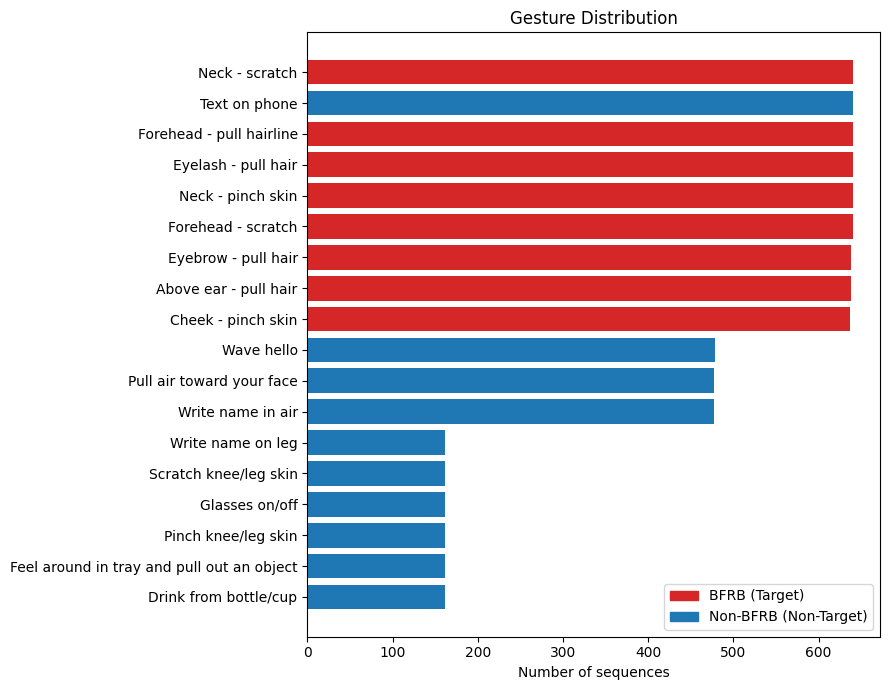

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

seq_info = train.groupby("sequence_id")[["gesture", "sequence_type"]].first()
counts = (seq_info.groupby(["gesture", "sequence_type"]).size()
          .reset_index(name="count").sort_values("count"))

colors = counts["sequence_type"].map({"Target": "tab:red", "Non-Target": "tab:blue"})

plt.figure(figsize=(9, 7))
plt.barh(counts["gesture"], counts["count"], color=colors)
plt.xlabel("Number of sequences")
plt.title("Gesture Distribution")
plt.legend(handles=[Patch(color="tab:red", label="BFRB (Target)"),
                    Patch(color="tab:blue", label="Non-BFRB (Non-Target)")])
plt.tight_layout()
plt.show()

**Findings:** The gestures form three groups by frequency: the 8 BFRB gestures and "Text on phone" (about 640 sequences each), three non-BFRB gestures (about 477 each), and six non-BFRB gestures (161 each). BFRB classes are balanced, while non-BFRB classes are imbalanced by a factor of about 4. Since the competition metric merges all non-BFRB gestures into a single class, this imbalance has a limited effect on the score.

## 9. Sequence Length Distribution (Plot)
**Purpose:** Visualize the distribution of sequence lengths to identify skewness and outliers.

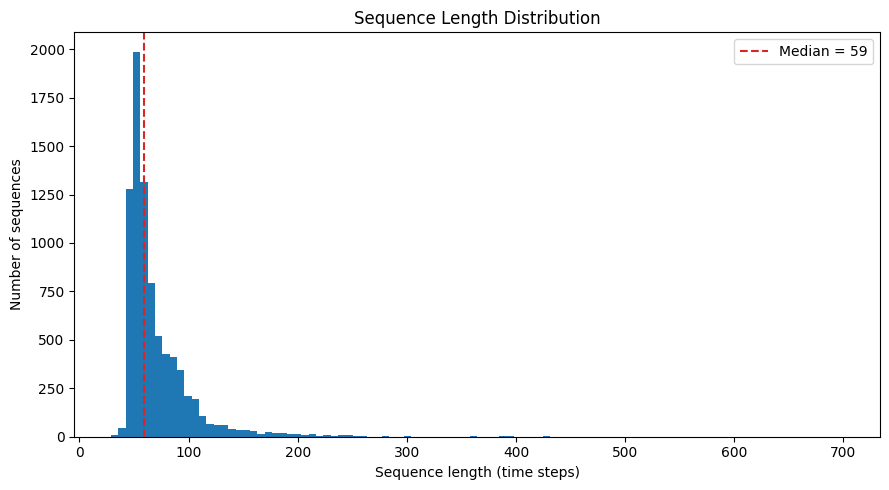

In [13]:
plt.figure(figsize=(9, 5))
plt.hist(seq_len, bins=100, color="tab:blue")
plt.axvline(seq_len.median(), color="tab:red", linestyle="--",
            label=f"Median = {seq_len.median():.0f}")
plt.xlabel("Sequence length (time steps)")
plt.ylabel("Number of sequences")
plt.title("Sequence Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

**Findings:** Most sequences are between 40 and 120 time steps long, with a peak around 50–60. The distribution has a long right tail: sequences longer than 200 steps are rare, and the longest (700 steps) is an extreme outlier. For models that require fixed-length input, a length around the 90th–95th percentile could be used, padding shorter sequences and truncating longer ones.

## 10. Missing Values
**Purpose:** Measure the percentage of missing values in each sensor group (IMU, thermopile, ToF).

In [14]:
imu_cols = [c for c in train.columns if c.startswith(("acc_", "rot_"))]
thm_cols = [c for c in train.columns if c.startswith("thm_")]
tof_cols = [c for c in train.columns if c.startswith("tof_")]

sensor_groups = {"IMU": imu_cols, "Thermopile": thm_cols, "ToF": tof_cols}

for name, cols in sensor_groups.items():
    missing = train[cols].isna().mean().mean() * 100
    print(f"{name}: {len(cols)} columns, {missing:.2f}% missing")

IMU: 7 columns, 0.37% missing
Thermopile: 5 columns, 2.11% missing
ToF: 320 columns, 1.91% missing


**Findings:** Missing values (NaN) are rare in the training data: 0.37% for IMU, 2.11% for thermopile, and 1.91% for ToF. Note that about half of the hidden test set contains only IMU data, so the model must also work without thermopile and ToF sensors. In addition, ToF sensors record -1 when no object is detected, which is not counted as NaN and is examined separately below.

## 11. ToF "No Detection" Values
**Purpose:** Measure how often ToF pixels report -1 (no object detected).

In [15]:
tof_values = train[tof_cols]
no_detection = (tof_values == -1).mean().mean() * 100
print(f"ToF pixels with -1 (no detection): {no_detection:.2f}%")

print("\nBy sequence type:")
for seq_t in ["Target", "Non-Target"]:
    rows = train["sequence_type"] == seq_t
    pct = (tof_values[rows] == -1).mean().mean() * 100
    print(f"  {seq_t}: {pct:.2f}%")

ToF pixels with -1 (no detection): 57.49%

By sequence type:
  Target: 50.72%
  Non-Target: 67.57%


**Findings:** 57.49% of ToF pixel values are -1 (no object detected), which is far more common than NaN. The rate is lower in BFRB sequences (50.72%) than in non-BFRB sequences (67.57%), suggesting that ToF sensors detect nearby objects (e.g. the face or head) more often during BFRBs. Therefore, -1 values carry information and should not be treated as simple missing data.

## Basic Statistics
**Purpose:** Summarize the numeric sensor columns (range, mean, spread) and the categorical metadata columns (number of unique values), to detect outliers and implausible values.

In [16]:
# Categorical / metadata columns
display(train.select_dtypes("object").describe().T)

# IMU and thermopile columns
display(train[imu_cols + thm_cols].describe().T.round(2))

# ToF columns: ignore -1 (no detection) and summarize per sensor
tof_valid = train[tof_cols].where(train[tof_cols] != -1)
tof_stats = pd.DataFrame({
    "min": tof_valid.min().groupby(lambda c: c.split("_")[1]).min(),
    "mean": tof_valid.mean().groupby(lambda c: c.split("_")[1]).mean(),
    "max": tof_valid.max().groupby(lambda c: c.split("_")[1]).max(),
})
tof_stats.index = "tof_" + tof_stats.index
display(tof_stats.round(2))

,count,unique,top,freq
row_id,574945,574945,SEQ_000007_000000,1
sequence_type,574945,2,Target,344058
sequence_id,574945,8151,SEQ_015261,700
subject,574945,81,SUBJ_040733,10848
orientation,574945,4,Seated Straight,188120
behavior,574945,4,Performs gesture,255817
phase,574945,2,Transition,319128
gesture,574945,18,Text on phone,58462


,count,mean,std,min,25%,50%,75%,max
acc_x,574945.0,1.64,5.78,-34.59,-2.96,2.97,6.34,46.33
acc_y,574945.0,1.79,5.00,-24.40,-2.12,0.70,6.82,27.18
acc_z,574945.0,-0.46,6.10,-42.86,-5.42,-1.56,5.16,30.08
rot_w,571253.0,0.36,0.23,0.00,0.18,0.34,0.50,1.00
rot_x,571253.0,-0.12,0.47,-1.00,-0.46,-0.19,0.20,1.00
rot_y,571253.0,-0.06,0.54,-1.00,-0.51,-0.11,0.44,1.00
rot_z,571253.0,-0.19,0.50,-1.00,-0.63,-0.26,0.25,1.00
thm_1,567958.0,27.08,3.23,-0.37,24.75,26.98,29.43,38.46
thm_2,567307.0,27.13,2.94,21.96,24.54,26.35,29.62,37.58
thm_3,568473.0,26.70,4.12,0.00,24.64,26.96,29.23,37.29


,min,mean,max
tof_1,0.0,111.18,249.0
tof_2,0.0,101.21,249.0
tof_3,0.0,104.84,249.0
tof_4,0.0,112.21,249.0
tof_5,0.0,109.19,249.0


**Findings:** The categorical columns contain 81 unique subject values and 18 unique gesture values (along with 8,151 unique sequences across 4 orientation and 4 behavior categories), consistent with the earlier analysis. The IMU columns span the following ranges: acc_x/y/z from -42.86 (acc_z min) to 46.33 (acc_x max), and the rotation quaternion components (rot_w/x/y/z) from -1.00 to 1.00 (rot_w ranges from 0.00 to 1.00). The thermopile columns (thm_1 to thm_5) range from -0.37 to 39.59 °C. ToF distances (ignoring -1 invalid/no-echo readings) span across the 0–254 mm sensor range and show consistent distributions across the five sensors (tof_1 to tof_5). Overall, no physically implausible values were found, though slight sub-zero/zero minimums in thm_1 (-0.37 °C) and thm_3 (0.00 °C) likely reflect brief sensor dropouts or ambient boundary noise rather than true body temperature, and acceleration extremes (~46 m/s²) correspond to rapid hand/arm movements.

## Duplicate Check
**Purpose:** Check that the data has no duplicated rows or identifiers, which would otherwise inflate the sample size and leak identical samples across cross-validation folds.

In [17]:
sensor_cols = imu_cols + thm_cols + tof_cols

print("Duplicate row_id:", train["row_id"].duplicated().sum())
print("Duplicate (sequence_id, sequence_counter):",
      train.duplicated(subset=["sequence_id", "sequence_counter"]).sum())
print("Rows with identical sensor values (within a sequence):",
      train.duplicated(subset=["sequence_id"] + sensor_cols).sum())
print("Rows with identical sensor values (anywhere):",
      train.duplicated(subset=sensor_cols).sum())

Duplicate row_id: 0
Duplicate (sequence_id, sequence_counter): 0
Rows with identical sensor values (within a sequence): 0
Rows with identical sensor values (anywhere): 0


**Findings:** There are no duplicated `row_id` values and no duplicated (`sequence_id`, `sequence_counter`) pairs, so every time step is uniquely identified. no rows have identical sensor values to another row.

## 12. Example Sensor Signals
**Purpose:** Compare raw acceleration and temperature signals of two similar motions performed at different body locations: "Neck - scratch" (BFRB) and "Scratch knee/leg skin" (non-BFRB).

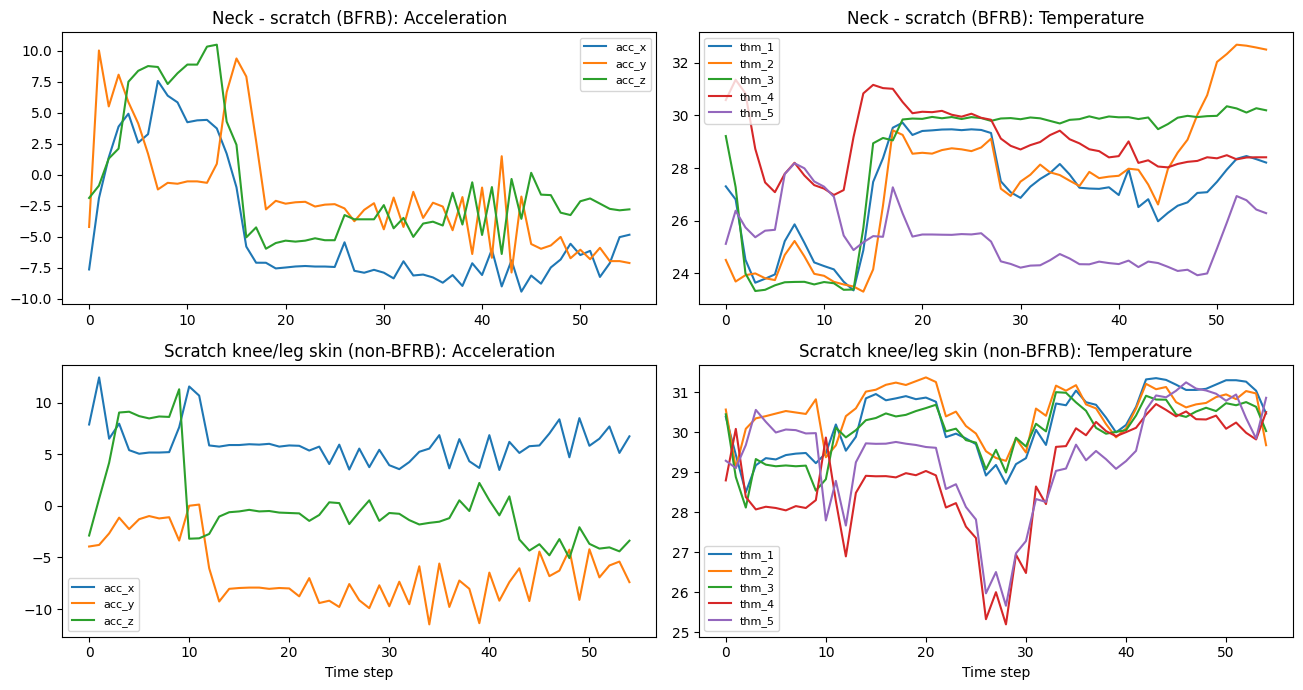

In [18]:
examples = {
    "Neck - scratch (BFRB)": "Neck - scratch",
    "Scratch knee/leg skin (non-BFRB)": "Scratch knee/leg skin",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for i, (title, gesture) in enumerate(examples.items()):
    seq_id = train.loc[train["gesture"] == gesture, "sequence_id"].iloc[0]
    seq = train[train["sequence_id"] == seq_id]
    t = seq["sequence_counter"]

    for col in ["acc_x", "acc_y", "acc_z"]:
        axes[i, 0].plot(t, seq[col], label=col)
    axes[i, 0].set_title(f"{title}: Acceleration")
    axes[i, 0].legend(fontsize=8)

    for col in thm_cols:
        axes[i, 1].plot(t, seq[col], label=col)
    axes[i, 1].set_title(f"{title}: Temperature")
    axes[i, 1].legend(fontsize=8)

for ax in axes[1]:
    ax.set_xlabel("Time step")

plt.tight_layout()
plt.show()

**Findings:** Both sequences follow the same structure: a transition phase in the first 10–15 time steps with large acceleration changes, followed by a steady phase with small, rapid oscillations corresponding to the scratching motion. The oscillation patterns look similar, so the motion itself is hard to distinguish. However, the acceleration levels in the steady phase differ (e.g. `acc_x` is about -7.5 for the neck and about +5 for the knee). Since acceleration at rest mainly reflects gravity, this shows that IMU data carries information about wrist orientation and therefore body location. In the temperature signals, the neck example shows a clear rise (from about 24 °C to about 30 °C) when the hand reaches the neck, while the knee example stays relatively high throughout. Temperature captures the timing of contact, but in these examples it does not clearly separate the two locations on its own. These observations are based on single examples and should be confirmed with aggregate statistics.

## 13. Participant Demographics
**Purpose:** Summarize participant information (age, sex, handedness, body measurements).

In [19]:
demo = pd.read_csv("data/train_demographics.csv")
print(demo.shape)
print(demo.columns.tolist())
demo.describe()

(81, 8)
['subject', 'adult_child', 'age', 'sex', 'handedness', 'height_cm', 'shoulder_to_wrist_cm', 'elbow_to_wrist_cm']


,adult_child,age,sex,handedness,height_cm,shoulder_to_wrist_cm,elbow_to_wrist_cm
count,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000
mean,0.518519,21.814815,0.617284,0.876543,167.993827,51.580247,25.469136
std,0.502770,10.289693,0.489078,0.331010,10.605863,4.888415,3.025254
min,0.000000,10.000000,0.000000,0.000000,135.000000,41.000000,18.000000
25%,0.000000,13.000000,0.000000,1.000000,163.000000,49.000000,24.000000
50%,1.000000,22.000000,1.000000,1.000000,170.000000,52.000000,25.000000
75%,1.000000,27.000000,1.000000,1.000000,174.000000,55.000000,27.000000
max,1.000000,53.000000,1.000000,1.000000,190.500000,71.000000,44.000000


**Findings:** The demographics file has one row per participant (81 participants, 8 columns). About half of the participants are children and half are adults, ages range from 10 to 53 (median 22), and height ranges from 135 to 190.5 cm. About 88% of participants are right-handed, so only around 10 are left-handed. If the device is worn on the dominant wrist, left-handed participants produce mirrored motion patterns, which may be hard for a model to learn from few examples. Differences in body size between children and adults may also affect sensor values such as distances and motion amplitude, which supports subject-based validation.

## 14. Baseline Setup
**Purpose:** Prepare sequence-level labels, the list of BFRB gestures, and the competition metric. As a sanity check, a perfect prediction should score 1.0.

In [20]:
labels = get_sequence_labels(train)
bfrb_gestures = labels.loc[labels["sequence_type"] == "Target", "gesture"].unique()
print("BFRB gestures:", len(bfrb_gestures))
print("Perfect prediction score:", competition_score(labels["gesture"], labels["gesture"], bfrb_gestures))

BFRB gestures: 8
Perfect prediction score: 1.0


**Findings:** The metric correctly returns 1.0 for a perfect prediction. There are 8 BFRB gestures; all other gestures are merged into a single non-BFRB class during scoring.

## 15. Baseline 1: Majority Class
**Purpose:** Predict the most frequent gesture for every sequence. This model learns nothing from sensor data and sets the lower bound for the score.

In [21]:
majority_gesture = labels["gesture"].value_counts().idxmax()
majority_pred = [majority_gesture] * len(labels)

majority_score = competition_score(labels["gesture"], majority_pred, bfrb_gestures)
print("Majority gesture:", majority_gesture)
print("Majority class score:", round(majority_score, 4))

Majority gesture: Forehead - pull hairline
Majority class score: 0.3936


**Findings:** The majority class baseline scores 0.3936. Because it predicts a BFRB gesture for every sequence and 63% of sequences are BFRBs, the binary F1 is relatively high, but the macro F1 is close to zero since only one of nine classes is ever predicted. Any useful model must clearly exceed this score.

## 16. Baseline 2: Random Forest (IMU Only)
**Purpose:** Train a random forest on sequence-level statistics (mean, std, min, max) of the 7 IMU columns, evaluated with 5-fold GroupKFold by subject. This corresponds to the IMU-only half of the test set.

In [22]:
groups = get_sensor_groups(train)
y = labels["gesture"]
subjects = labels["subject"]

X_imu = extract_features(train, groups["IMU"])
imu_scores, imu_oof = cross_validate(make_random_forest, X_imu, y, subjects, bfrb_gestures)

Fold 1: 0.6005
Fold 2: 0.6840
Fold 3: 0.6531
Fold 4: 0.6492
Fold 5: 0.6712
Mean: 0.6516 ± 0.0285


**Findings:** The IMU-only random forest scores 0.6516 ± 0.0285 across 5 folds, a large improvement over the majority class baseline (0.3936). Simple sequence-level statistics of acceleration and orientation already carry substantial information about the gesture. Fold scores range from 0.60 to 0.68, showing that performance varies depending on which subjects are held out.

## 17. Baseline 3: Random Forest (All Sensors)
**Purpose:** Add thermopile and ToF features to the IMU features. Each ToF sensor's 64 pixels are summarized per time step as the mean distance of detected pixels and the fraction of pixels with no detection (-1), then sequence-level statistics are computed as before.

In [23]:
tof_summary = summarize_tof(train)
tof_summary_cols = [c for c in tof_summary.columns if c != "sequence_id"]

X_thm = extract_features(train, groups["Thermopile"])
X_tof = extract_features(tof_summary, tof_summary_cols)
X_all = pd.concat([X_imu, X_thm, X_tof], axis=1)
print("Feature count:", X_all.shape[1])

all_scores, all_oof = cross_validate(make_random_forest, X_all, y, subjects, bfrb_gestures)

Feature count: 88
Fold 1: 0.6867
Fold 2: 0.7342
Fold 3: 0.7185
Fold 4: 0.7158
Fold 5: 0.7450
Mean: 0.7200 ± 0.0198


**Findings:** Adding thermopile and ToF features raises the score to 0.7200 ± 0.0198, compared to 0.6516 for IMU only. Since GroupKFold uses the same subject splits, folds can be compared directly, and the score improved in all five folds. The lower standard deviation also indicates more stable performance across subjects. This confirms the EDA observation that proximity and thermal information help distinguish BFRBs, which occur near the face and head, from similar non-BFRB motions.

## 18. Baseline Comparison
**Purpose:** Summarize the cross-validation scores of all baseline models. These results are the reference point for the proposed solution in Assignment 2.

In [24]:
import numpy as np

results = pd.DataFrame({
    "Model": ["Majority class", "Random Forest (IMU only)", "Random Forest (all sensors)"],
    "Features": [0, X_imu.shape[1], X_all.shape[1]],
    "CV score (mean)": [majority_score, np.mean(imu_scores), np.mean(all_scores)],
    "CV score (std)": [np.nan, np.std(imu_scores), np.std(all_scores)],
}).round(4)

results

,Model,Features,CV score (mean),CV score (std)
0,Majority class,0,0.3936,NaN
1,Random Forest (IMU only),28,0.6516,0.0285
2,Random Forest (all sensors),88,0.7200,0.0198


**Findings:** Each step improves the score: the majority class baseline scores 0.3936, the IMU-only random forest 0.6516, and the all-sensor random forest 0.7200. Sequence-level statistics are a strong starting point, and adding thermopile and ToF information gives a clear gain. In Assignment 2, the proposed solution will be compared against the all-sensor random forest (0.7200) as the main reference. Note that the majority class score is computed on the full dataset, since this model does not learn from the data.